# Modelagem

**Objetivo:** construir o modelo final que explica o valor de mercado dos jogadores a partir do perfil, do desempenho e do contexto do clube, e que serve de base para identificar jogadores sub e supervalorizados.

**Entrada:** `data/processado/features_modelo.csv`, `jogador_temporada.csv` e `jogos_brasileirao.csv`
**Saída:** `data/processado/features_contexto.csv`, `metricas_ablacao.csv`, `metricas_modelos.csv`, `ajuste_hiperparametros.csv`, `metricas_modelo_final.csv`, `models/modelo_final.joblib` e `models/modelo_final.json`

**Reprodutibilidade:** a semente `SEED = 42` fica em `scripts/modelagem.py` e é usada em tudo que tem aleatoriedade (K-Fold embaralhado, target encoding, modelos de árvore, ElasticNet e importância por permutação). O GroupKFold não embaralha, então é sempre igual.

In [1]:
import sys
sys.path.append("../scripts")

import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, GroupKFold

from variaveis_contexto import montar_features_contexto
from modelagem import SEED, ALVO, GRUPO, COLUNAS_BASE, COLUNAS_FINAIS, FORCA_CLUBE, GRADES, PARTICIPACAO
from modelagem import avaliar_modelos, construir_modelos_ablacao, construir_modelos_finais
from modelagem import metricas_em_euros, metricas_por_fold, previsoes_oof

features = pd.read_csv("../data/processado/features_modelo.csv")
jogador_temporada = pd.read_csv("../data/processado/jogador_temporada.csv")
jogos_brasileirao = pd.read_csv("../data/processado/jogos_brasileirao.csv")

np.random.seed(SEED)
print("SEED:", SEED)

SEED: 42


## Erros do baseline

Antes de testar modelos novos, olhamos onde o `ridge_completo` (melhor modelo do 005) erra. Os resíduos (log real − log previsto) são calculados fora da amostra: cada jogador é previsto por um modelo que nunca o viu (GroupKFold).

In [2]:
fabrica_base = construir_modelos_ablacao()["ridge_completo"][0]

diag = features[["season", "player_id", "clube_temporada", "minutos_jogados", ALVO]].copy()
diag["residuo"] = diag[ALVO] - previsoes_oof(features, fabrica_base, COLUNAS_BASE)

por_clube = diag.groupby("clube_temporada")["residuo"].agg(residuo_medio="mean", n="size")
por_clube = por_clube.sort_values("residuo_medio")
por_clube["fator_aprox"] = np.exp(por_clube["residuo_medio"]).round(2)

print(f"Desvio do resíduo médio entre clubes: {por_clube['residuo_medio'].std():.3f}")
print()
print("Resíduo médio por temporada:")
print(diag.groupby("season")["residuo"].mean().round(3).to_string())
print()
print("Minutos jogados por temporada (mediana):")
print(diag.groupby("season")["minutos_jogados"].median().to_string())

Desvio do resíduo médio entre clubes: 0.557

Resíduo médio por temporada:
season
2024   -0.029
2025    0.068

Minutos jogados por temporada (mediana):
season
2024    1710.0
2025    1172.0


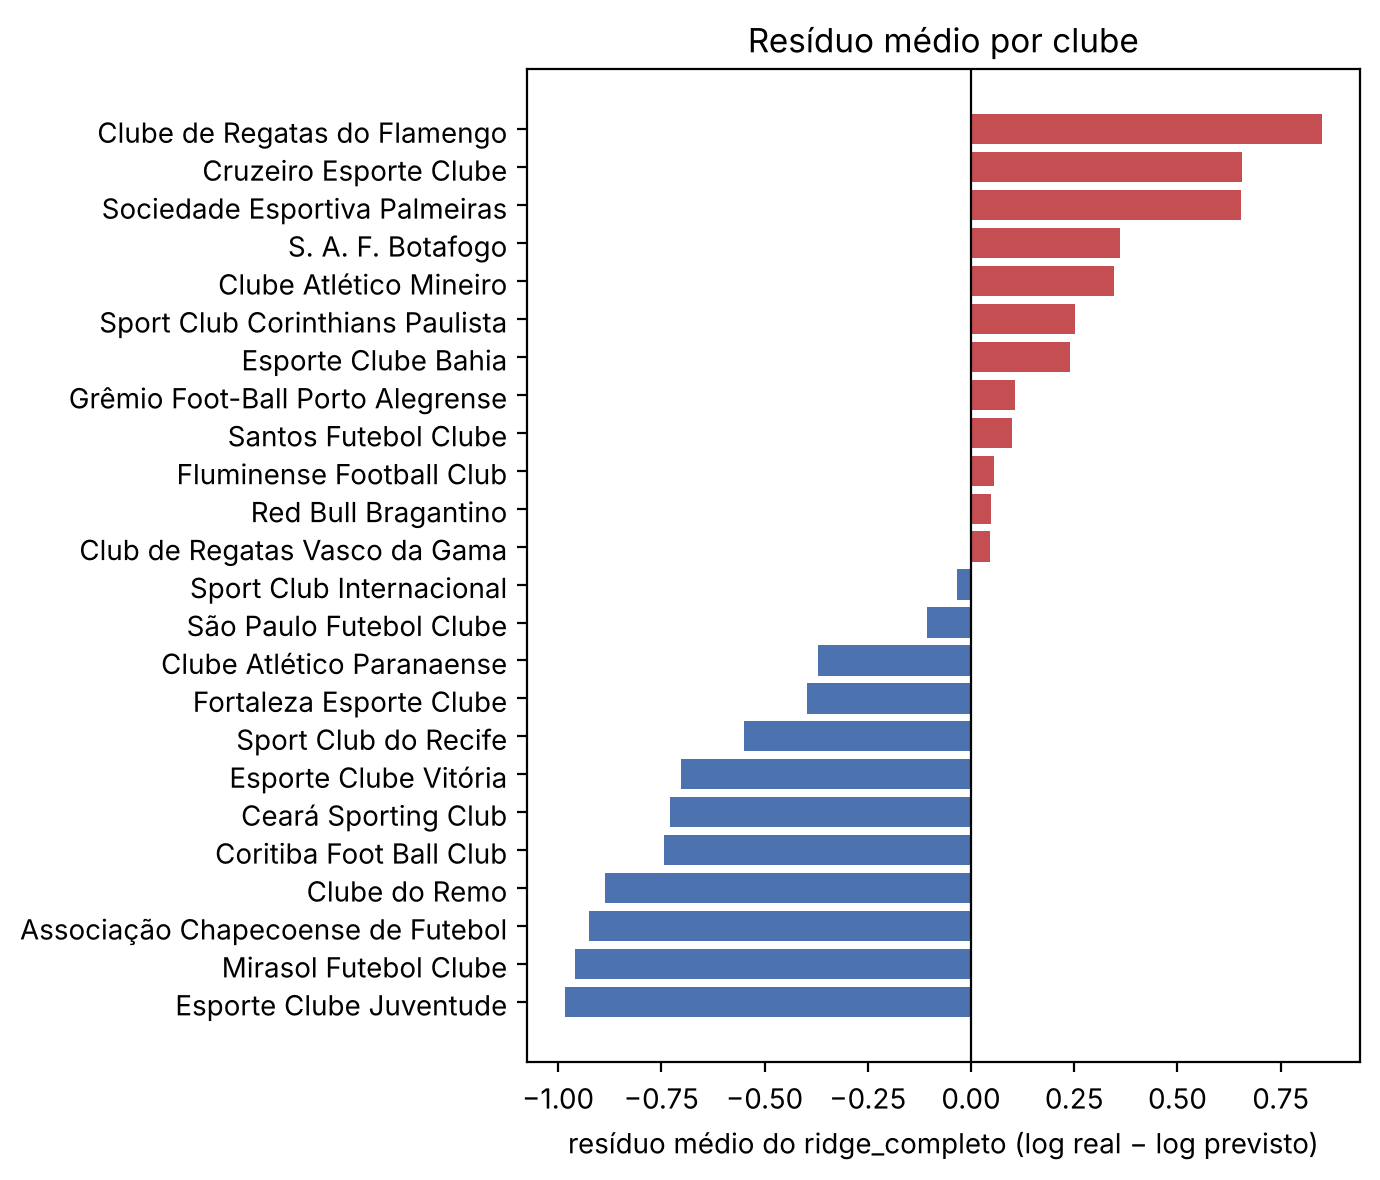

In [3]:
cores = np.where(por_clube["residuo_medio"] > 0, "#C44E52", "#4C72B0")

fig, eixo = plt.subplots(figsize=(7, 6))
eixo.barh(por_clube.index, por_clube["residuo_medio"], color=cores)
eixo.axvline(0, color="black", linewidth=0.8)
eixo.set_xlabel("resíduo médio do ridge_completo (log real − log previsto)")
eixo.set_title("Resíduo médio por clube")
plt.tight_layout()

fig.savefig("../figuras/residuo_medio_por_clube.png")
plt.show()

- Clube: o erro médio muda muito de um clube para outro (desvio de 0,56). O modelo subestima clubes grandes como Flamengo, Cruzeiro e Palmeiras e superestima clubes menores como Juventude, Mirassol e Chapecoense. Falta informação do clube.
- Temporada: 2025 é subestimada (resíduo médio de +0,07). Minutos e jogos são totais acumulados e 2025 tem só ~18 rodadas, por isso a mediana de minutos cai de 1.710 para 1.172.

Por isso vamos criar variáveis de contexto.

## Variáveis de contexto

- `participacao_minutos` e `participacao_jogos`: minutos e jogos em relação aos jogos do clube na temporada. Substituem os totais acumulados.
- `participacao_gols_clube`: gols + assistências em relação aos gols do clube.
- `sub_*`: subposição em 0/1 (zagueiro, lateral, volante, meia, ponta, centroavante...). Substitui `pos_*`.
- `pontos_por_jogo_clube` e `saldo_gols_por_jogo_clube`: desempenho do clube na temporada.
- `clube_temporada`: entra com target encoding, ou seja, vira o valor médio (em log) dos jogadores do clube.

Nenhuma variável usa o valor de mercado do próprio jogador. O target encoding é calculado dentro do pipeline, só com o treino de cada fold, e clube que não aparece no treino recebe a média geral.

In [4]:
df = montar_features_contexto(features, jogador_temporada, jogos_brasileirao)

assert len(df) == len(features)
assert not df.duplicated(["season", "player_id"]).any()

nulos = df[PARTICIPACAO + FORCA_CLUBE + ["sub_position"]].isna().sum()
print("Colunas com nulos nas variáveis novas:")
print(nulos[nulos > 0].to_string())

df.to_csv("../data/processado/features_contexto.csv", index=False)
df.groupby("season")[["minutos_jogados", "participacao_minutos", "participacao_jogos"]].median().round(2)

Colunas com nulos nas variáveis novas:
Series([], )


,minutos_jogados,participacao_minutos,participacao_jogos
season,,,
2024,1710.0,0.50,0.68
2025,1172.0,0.75,0.83


- A participação mediana é 0,50 em 2024 e 0,75 em 2025. O corte de 900 minutos do 002 pesa diferente nas duas temporadas: em 2025 só entra quem jogou pelo menos ~55% dos minutos possíveis, em 2024 bastam ~26%. Por isso a amostra de 2025 é quase só de titulares, e a participação sozinha não resolve isso.

## Ablação

Mesmo modelo (Ridge) e mesmas validações do baseline, acrescentando um bloco de variáveis por vez para ver quanto cada um acrescenta.

In [5]:
modelos_ablacao = construir_modelos_ablacao()
ablacao = avaliar_modelos(df, modelos_ablacao)
ablacao.to_csv("../data/processado/metricas_ablacao.csv", index=False)

ordem_ablacao = list(modelos_ablacao)


def tabela(resultados, validacao, ordem):
    t = resultados[resultados["validacao"] == validacao].set_index("modelo").loc[ordem]
    ref = t.loc["ridge_completo"]
    out = pd.DataFrame({
        "R2_log": t["R2_log"].round(3),
        "ganho_R2_vs_baseline": (t["R2_log"] - ref["R2_log"]).round(3),
        "MAE_log": t["MAE_log"].round(3),
        "MAE_eur": t["MAE_eur"].round(0),
        "reducao_MAE_vs_baseline": ((1 - t["MAE_eur"] / ref["MAE_eur"]) * 100).round(1).astype(str) + "%",
    })
    return out


print("GroupKFold por jogador (validação principal)")
display(tabela(ablacao, "groupkfold_5", ordem_ablacao))
print("Holdout temporal (treino 2024, teste 2025)")
display(tabela(ablacao, "holdout_temporal", ordem_ablacao))

GroupKFold por jogador (validação principal)


,R2_log,ganho_R2_vs_baseline,MAE_log,MAE_eur,reducao_MAE_vs_baseline
modelo,,,,,
ridge_completo,0.528,0.000,0.659,2503123.0,0.0%
ridge_+participacao,0.538,0.010,0.651,2444861.0,2.3%
ridge_+subposicao,0.535,0.007,0.658,2481629.0,0.9%
ridge_+forca_clube,0.588,0.060,0.607,2289321.0,8.5%
ridge_+clube,0.692,0.164,0.525,2032537.0,18.8%


Holdout temporal (treino 2024, teste 2025)


,R2_log,ganho_R2_vs_baseline,MAE_log,MAE_eur,reducao_MAE_vs_baseline
modelo,,,,,
ridge_completo,0.615,0.000,0.674,2967454.0,0.0%
ridge_+participacao,0.628,0.013,0.671,2926424.0,1.4%
ridge_+subposicao,0.623,0.008,0.671,2929523.0,1.3%
ridge_+forca_clube,0.675,0.060,0.616,2722861.0,8.2%
ridge_+clube,0.716,0.100,0.574,2379028.0,19.8%


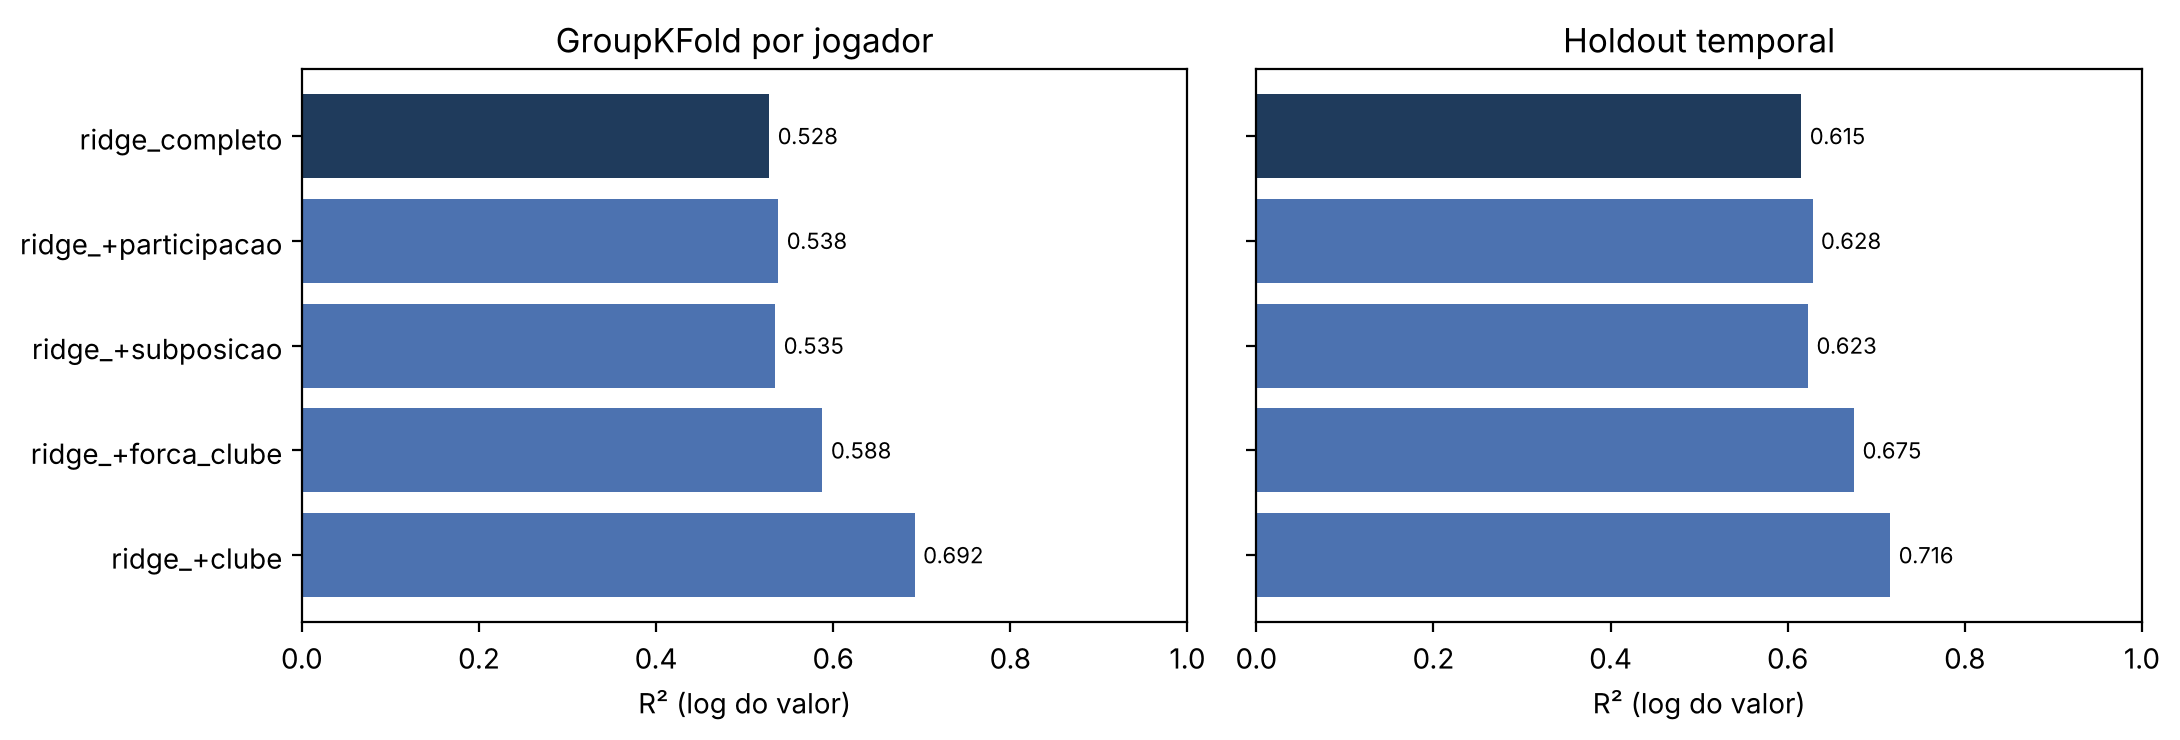

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for eixo, validacao, titulo in [(eixos[0], "groupkfold_5", "GroupKFold por jogador"), (eixos[1], "holdout_temporal", "Holdout temporal")]:
    t = ablacao[ablacao["validacao"] == validacao].set_index("modelo").loc[ordem_ablacao]
    cores = ["#1F3B5C" if m == "ridge_completo" else "#4C72B0" for m in t.index[::-1]]
    barras = eixo.barh(t.index[::-1], t["R2_log"][::-1], color=cores)
    eixo.bar_label(barras, fmt="%.3f", padding=3, fontsize=8)
    eixo.set_xlim(0, 1)
    eixo.set_title(titulo)
    eixo.set_xlabel("R² (log do valor)")
plt.tight_layout()

fig.savefig("../figuras/modelagem_ablacao_r2.png")
plt.show()

- Participação e subposição acrescentam pouco (cerca de +0,01 de R²).
- A força do clube sobe o R² em +0,06 e o clube mais +0,10. No holdout o R² vai de 0,615 para 0,716.
- O erro em euros cai cerca de 20% em relação ao `ridge_completo`.

## Comparação de algoritmos

Com o clube e a subposição pode haver interações (por exemplo, a idade pesar diferente em clube grande), então testamos modelos de árvore com todas as variáveis.

In [7]:
modelos = construir_modelos_finais()
resultados = avaliar_modelos(df, modelos)

metricas = pd.concat([ablacao[ablacao["modelo"] == "ridge_completo"], resultados], ignore_index=True)
metricas.to_csv("../data/processado/metricas_modelos.csv", index=False)

ordem = ["ridge_completo"] + list(modelos)
print("GroupKFold por jogador")
display(tabela(metricas, "groupkfold_5", ordem))
print("Holdout temporal")
display(tabela(metricas, "holdout_temporal", ordem))

GroupKFold por jogador


,R2_log,ganho_R2_vs_baseline,MAE_log,MAE_eur,reducao_MAE_vs_baseline
modelo,,,,,
ridge_completo,0.528,0.000,0.659,2503123.0,0.0%
ridge,0.692,0.164,0.525,2032537.0,18.8%
elasticnet,0.680,0.152,0.542,2138558.0,14.6%
random_forest,0.699,0.171,0.538,2076871.0,17.0%
gradient_boosting,0.702,0.174,0.524,1980758.0,20.9%
hist_gradient_boosting,0.665,0.137,0.567,2145383.0,14.3%


Holdout temporal


,R2_log,ganho_R2_vs_baseline,MAE_log,MAE_eur,reducao_MAE_vs_baseline
modelo,,,,,
ridge_completo,0.615,0.000,0.674,2967454.0,0.0%
ridge,0.716,0.100,0.574,2379028.0,19.8%
elasticnet,0.702,0.087,0.587,2420990.0,18.4%
random_forest,0.701,0.085,0.610,2584883.0,12.9%
gradient_boosting,0.696,0.080,0.599,2428647.0,18.2%
hist_gradient_boosting,0.689,0.073,0.610,2412445.0,18.7%


,mean,std,min,max
modelo,,,,
ridge,0.692,0.050,0.628,0.765
elasticnet,0.681,0.053,0.610,0.755
random_forest,0.699,0.012,0.687,0.716
gradient_boosting,0.702,0.022,0.668,0.728
hist_gradient_boosting,0.665,0.017,0.643,0.687


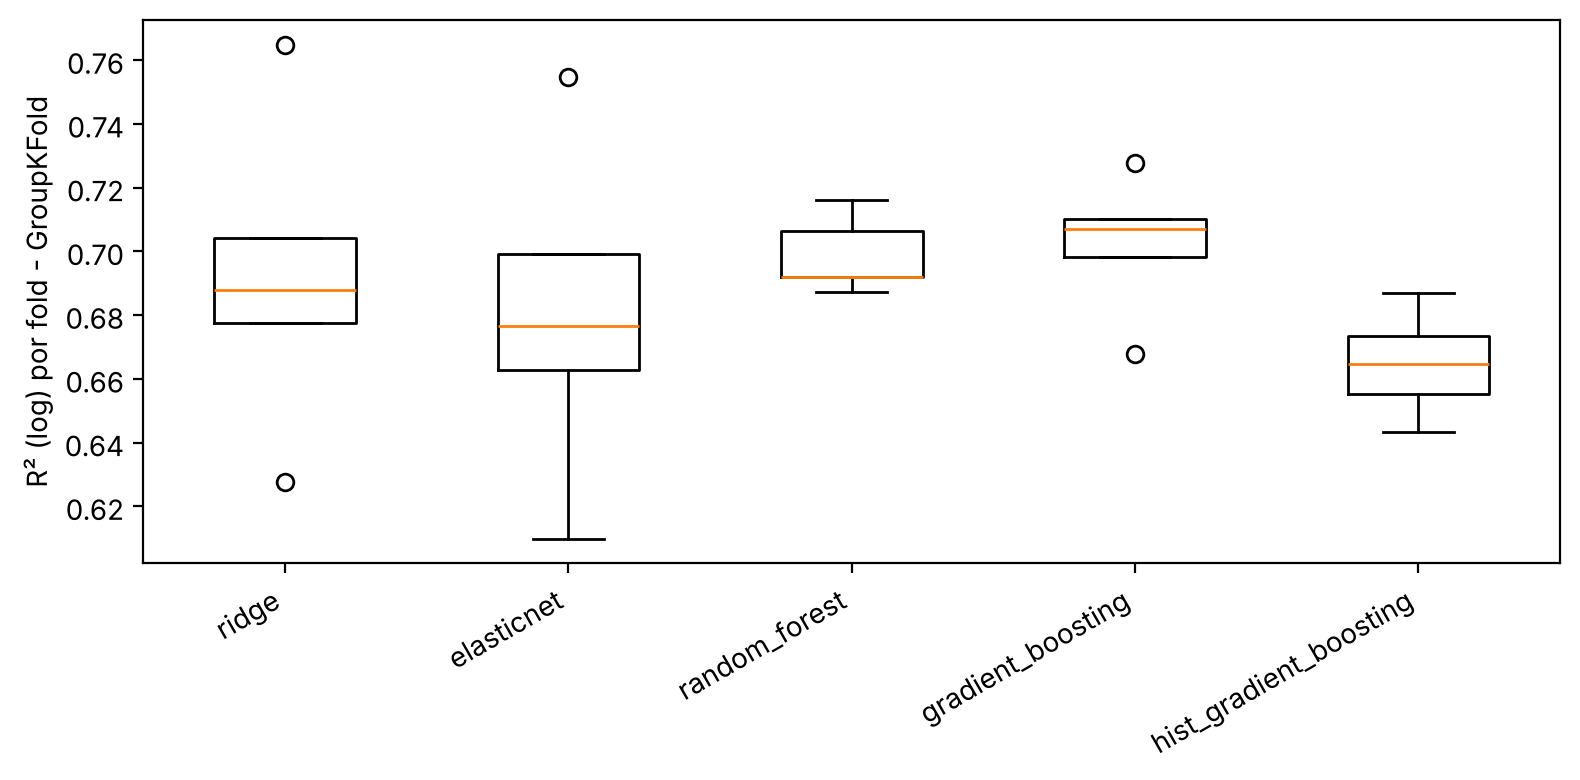

In [8]:
por_fold = metricas_por_fold(df, modelos)
display(por_fold.groupby("modelo")["R2_log"].agg(["mean", "std", "min", "max"]).loc[list(modelos)].round(3))

fig, eixo = plt.subplots(figsize=(8, 4))
eixo.boxplot([por_fold.loc[por_fold["modelo"] == m, "R2_log"] for m in modelos])
eixo.set_xticks(range(1, len(modelos) + 1), list(modelos), rotation=30, ha="right")
eixo.set_ylabel("R² (log) por fold - GroupKFold")
plt.tight_layout()

fig.savefig("../figuras/modelagem_r2_por_fold.png")
plt.show()

- No GroupKFold, Random Forest e Gradient Boosting ficam um pouco acima do Ridge (0,70 contra 0,69), mas no holdout o Ridge é o melhor (0,716).
- As diferenças são menores que a variação entre folds (desvio de 0,01 a 0,05).

## Ajuste de hiperparâmetros e escolha do modelo final

- O ajuste é feito só com 2024 (GridSearchCV + GroupKFold). 2025 fica de fora até o fim.
- O critério é o R² médio da validação em 2024.
- Se o melhor modelo não ganhar do Ridge por mais de um desvio padrão entre folds, fica o Ridge, que é mais simples e interpretável.

In [9]:
treino = df["temporada_completa"] == True
teste = df["temporada_completa"] == False

X_treino, y_treino, grupos_treino = df.loc[treino, COLUNAS_FINAIS], df.loc[treino, ALVO], df.loc[treino, GRUPO]
X_teste, y_teste = df.loc[teste, COLUNAS_FINAIS], df.loc[teste, ALVO]

buscas = {}
linhas = []
for nome, grade in GRADES.items():
    busca = GridSearchCV(modelos[nome][0](), grade, cv=GroupKFold(n_splits=5), scoring="r2", n_jobs=-1)
    busca.fit(X_treino, y_treino, groups=grupos_treino)
    buscas[nome] = busca

    i = busca.best_index_
    metricas_holdout = metricas_em_euros(y_teste.to_numpy(), busca.best_estimator_.predict(X_teste))
    linha = {
        "modelo": nome,
        "melhores_params": busca.best_params_,
        "R2_cv_2024": busca.cv_results_["mean_test_score"][i],
        "desvio_cv_2024": busca.cv_results_["std_test_score"][i],
    }
    for k, v in metricas_holdout.items():
        linha[f"{k}_holdout"] = v
    linhas.append(linha)

ajuste = pd.DataFrame(linhas).sort_values("R2_cv_2024", ascending=False).set_index("modelo")
ajuste.to_csv("../data/processado/ajuste_hiperparametros.csv")
ajuste.round(3)

,melhores_params,R2_cv_2024,desvio_cv_2024,MAE_eur_holdout,RMSE_eur_holdout,R2_log_holdout,MAE_log_holdout
modelo,,,,,,,
elasticnet,"{'modelo__alpha': 0.001, 'modelo__l1_ratio': 0.5}",0.618,0.036,2359858.263,3974190.418,0.723,0.566
ridge,{'modelo__alpha': 0.1},0.618,0.035,2366141.924,3977954.852,0.724,0.567
gradient_boosting,"{'modelo__learning_rate': 0.02, 'modelo__max_d...",0.614,0.064,2750067.435,4553325.287,0.654,0.648
random_forest,"{'modelo__max_depth': 8, 'modelo__max_features...",0.602,0.081,2594903.477,4282075.900,0.682,0.628
hist_gradient_boosting,"{'modelo__l2_regularization': 0.0, 'modelo__le...",0.573,0.077,2502577.898,4057348.887,0.670,0.625


In [10]:
melhor = ajuste["R2_cv_2024"].idxmax()
ganho = ajuste.loc[melhor, "R2_cv_2024"] - ajuste.loc["ridge", "R2_cv_2024"]
desvio = ajuste.loc[melhor, "desvio_cv_2024"]

if melhor != "ridge" and ganho <= desvio:
    nome_final = "ridge"
    motivo = f"{melhor} ganhou só {ganho:.3f} de R² sobre o Ridge, menos que o desvio entre folds ({desvio:.3f}). Pela parcimônia, fica o Ridge."
else:
    nome_final = melhor
    motivo = f"{melhor} teve o maior R² na validação de 2024 (ganho de {ganho:.3f} sobre o Ridge, desvio {desvio:.3f})."

params_finais = buscas[nome_final].best_params_
print("Modelo final:", nome_final, params_finais)
print(motivo)
print()
print("Holdout 2025 (nunca usado na escolha):")
ajuste[["R2_log_holdout", "MAE_log_holdout", "MAE_eur_holdout"]].round(3)

Modelo final: ridge {'modelo__alpha': 0.1}
elasticnet ganhou só 0.000 de R² sobre o Ridge, menos que o desvio entre folds (0.036). Pela parcimônia, fica o Ridge.

Holdout 2025 (nunca usado na escolha):


,R2_log_holdout,MAE_log_holdout,MAE_eur_holdout
modelo,,,
elasticnet,0.723,0.566,2359858.263
ridge,0.724,0.567,2366141.924
gradient_boosting,0.654,0.648,2750067.435
random_forest,0.682,0.628,2594903.477
hist_gradient_boosting,0.670,0.625,2502577.898


- ElasticNet e Ridge empatam em 2024 (R² de 0,618), por isso fica o Ridge com `alpha = 0,1`.
- No holdout 2025 o Ridge ajustado chega a R² de 0,724 e erro médio de cerca de € 2,37 milhões.

## Modelo final x baseline

As mesmas três validações do 005. No GroupKFold e no K-Fold os hiperparâmetros foram escolhidos com 2024, então esses números ficam um pouco otimistas; o holdout é o mais confiável.

In [11]:
fabrica_escolhida, colunas_finais, _ = modelos[nome_final]


def fabrica_final():
    return fabrica_escolhida().set_params(**params_finais)


final = avaliar_modelos(df, {f"{nome_final}_ajustado": (fabrica_final, colunas_finais, "modelo final")})
final.to_csv("../data/processado/metricas_modelo_final.csv", index=False)

comparacao = pd.concat([ablacao[ablacao["modelo"] == "ridge_completo"], final])
comparacao.pivot_table(index="validacao", columns="modelo", values=["R2_log", "MAE_log", "MAE_eur"]).round(3)

MAE_eur                       MAE_log                 \
modelo            ridge_ajustado ridge_completo ridge_ajustado ridge_completo   
validacao                                                                       
groupkfold_5         1988252.471    2503122.822          0.522          0.659   
holdout_temporal     2366141.924    2967454.177          0.567          0.674   
kfold_5_aleatorio    1978442.966    2522591.799          0.517          0.665   

                          R2_log                 
modelo            ridge_ajustado ridge_completo  
validacao                                        
groupkfold_5               0.695          0.528  
holdout_temporal           0.724          0.615  
kfold_5_aleatorio          0.699          0.510

- O R² vai de 0,528 para 0,695 no GroupKFold e de 0,615 para 0,724 no holdout.
- O MAE em log cai de 0,674 para 0,567 no holdout: a previsão passa a errar por um fator de cerca de 1,8 (antes ~2).

## Salvando o modelo

In [12]:
os.makedirs("../models", exist_ok=True)

modelo_final = fabrica_final().fit(df[colunas_finais], df[ALVO])
joblib.dump(modelo_final, "../models/modelo_final.joblib")

info = {
    "nome": nome_final,
    "hiperparametros": params_finais,
    "colunas": colunas_finais,
    "alvo": ALVO,
    "motivo_escolha": motivo,
    "metricas": final.drop(columns=["nivel", "modelo"]).set_index("validacao").round(4).to_dict(orient="index"),
}
with open("../models/modelo_final.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2, default=str)

print("Salvo em models/modelo_final.joblib e models/modelo_final.json")

Salvo em models/modelo_final.joblib e models/modelo_final.json


## Conclusões

- O clube é o que mais melhora o modelo: o mercado valoriza o jogador também pelo clube em que ele está.
- Os modelos de árvore não superam o Ridge, então a relação entre as variáveis e o log do valor é praticamente linear.
- O modelo explica cerca de 70% da variação do valor (em log). O resto vem de coisas que a base não tem, como reputação, seleção e histórico fora do Brasileirão.
- O viés de 2025 continua (resíduo médio de +0,06) por causa do corte de 900 minutos. Fica como limitação.